<a href="https://colab.research.google.com/github/ZaDs-sisadm/AI_Politechnika/blob/lab_1/transformers_task_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна 3. Токенізація та трансформери

**Студент:** Зайцев Денис Сергійович  
**Корпус:** українська Вікіпедія (`wikimedia/wikipedia`, конфіг `20231101.uk`).

Ноутбук запускається зверху донизу (Run All). Для тренування mini-GPT потрібен GPU (Colab T4 достатньо); на CPU ноутбук спрацює, але з урізаною кількістю ітерацій.

In [3]:
%pip install -q "transformers[sentencepiece]==5.18.0" datasets tokenizers evaluate seqeval scikit-learn tensorboard gradio accelerate

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:
import os, gc, re, time, math, random, shutil, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from torch.utils.tensorboard import SummaryWriter

SEED = 42
def set_seed(seed: int = SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE_ID = 0 if device.type == "cuda" else -1       # для pipeline()
print("device:", device)
if device.type == "cpu":
    print("УВАГА: GPU не знайдено — mini-GPT тренуватиметься з урізаною кількістю ітерацій.")

MODELS_DIR, RUNS_DIR, RESULTS_PATH = "models", "runs", "results.csv"
shutil.rmtree(RUNS_DIR, ignore_errors=True)
os.makedirs(MODELS_DIR, exist_ok=True); os.makedirs(RUNS_DIR, exist_ok=True)
RESULT_ROWS = []     # зведені результати для results.csv (секції 3 і 5)

device: cpu
УВАГА: GPU не знайдено — mini-GPT тренуватиметься з урізаною кількістю ітерацій.


---
## 0. Відповіді на теоретичні питання

> Демо-ноутбук лекції 4 мені був недоступний, тому відповіді сформульовані на основі логіки відповідних алгоритмів і мого власного коду нижче (кожен розділ демо я відтворив у своїй реалізації). Для питань, що потребують експерименту, відповідь формується автоматично з результатів запуску в цьому ноутбуці — вказано, у якій клітинці.

### 0.2. Мої відповіді

**1. Тренер BPE отримує список віршів, а не один склеєний рядок. Що б змінилось?**  
BPE-тренер після нормалізації і pre-tokenization рахує частоти пар усередині «слів», і злиття не перетинають межі слів. Тому набір злиттів від склеювання майже не змінився б. Зламалось би інше, практичне:
- зникли б **межі документів**: з одним рядком неможливо ні закодувати вірші окремо, ні вставити `<eos>` між ними (див. питання 4);
- тренер отримав би **один гігантський елемент** замість потоку маленьких: немає пакетної обробки й паралелізму, різкий пік пам'яті, а на великому корпусі — OOM;
- втрачається можливість рахувати статистику «на документ» (середня довжина, частка `<unk>` на вірш тощо).

**2. З яких етапів складається токенізація?**
1. **Normalization** — очищення тексту: Unicode-нормалізація (NFC/NFD), lowercase, прибирання акцентів і зайвих пробілів.
2. **Pre-tokenization** — розбиття тексту на «слова» (за пробілами/пунктуацією, на рівні байтів або з маркером `▁`). Визначає межі, через які злиття не проходять.
3. **Model** — власне алгоритм підслів (BPE, WordPiece, Unigram): розбиває кожне слово на токени зі словника й повертає їхні id.
4. **Post-processing** — додавання спеціальних токенів за шаблоном (`[CLS]`/`[SEP]`, `<eos>`), маски уваги, truncation/padding.

Зворотний шлях — **decoding**: id → токени → текст.

**2 (друге). Що таке `<unk>` і `<eos>`?**  
`<unk>` — токен для символів/фрагментів, яких немає у словнику токенізатора («невідоме»). `<eos>` (end of sequence) — службовий токен кінця документа/послідовності; у навчанні він розділяє незалежні тексти, а під час генерації сигналізує, що модель закінчила.

**3. Менший `VOCAB_SIZE`: `<unk>` і довжина послідовностей.** Експеримент і числа — у клітинці «Експеримент до питання 3» (розділ 3.1), текст-висновок формується автоматично. Пояснення: словник = базовий алфавіт (символи або 256 байтів) + злиття. Зменшення `VOCAB_SIZE` скорочує лише кількість злиттів, а базовий алфавіт лишається, тому будь-який символ, що був у корпусі, і далі представлений — частка `<unk>` не росте (для byte-level BPE вона нульова за побудовою). Але з меншою кількістю злиттів слова розпадаються на більше коротких шматків, тож закодовані послідовності довшшають. Через це при фіксованому `CONTEXT_LEN` вікно в N токенів покриває **менше тексту**, моделі треба більше токенів і кроків, щоб побачити той самий текст, а генерація того самого обсягу тексту коштує більше кроків.

**4. Навіщо `<eos>` між документами?**  
Корпус для mini-GPT — це один довгий потік токенів. Без `<eos>` кінець однієї статті безпосередньо переходить у початок іншої, і модель вчиться «продовжувати» стаття A текстом статті B, хоча вони не пов'язані; вікна контексту, що перетинають межу, містять шум. Головне: модель ніколи не бачить сигналу «текст закінчено», тому не вчиться завершувати текст, і під час генерації не може сама зупинитись.

**5. Формат `train_data` і `val_data`.**  
Це одновимірні тензори `torch.int64` довжиною у загальну кількість токенів відповідного спліту. Кожен елемент — **id токена** (індекс у словнику, число від 0 до `VOCAB_SIZE-1`), а не one-hot. Документи йдуть підряд, розділені id токена `<eos>`. Із цього потоку `get_batch` вирізає випадкові вікна довжини `CONTEXT_LEN` (`x`) та такі ж вікна, зсунуті на 1 токен праворуч (`y`) — мета: передбачити наступний токен. Клітинка «Перевірка формату» нижче це показує.

**6. `assert` до батча** — код у клітинці «Питання 6» (розділ 3.1).

**7. Чому маска нижньотрикутна?**  
Рядок `i` матриці уваги — це запит (позиція `i`), стовпець `j` — ключ (позиція `j`). Нижньотрикутна маска дозволяє `j ≤ i`, тобто токен бачить себе і **лише попередні** токени. Верхньотрикутна дозволила б дивитись у майбутнє, що суперечить авторегресивній задачі. Без маски під час тренування модель бачила б правильну відповідь (наступний токен) у своєму ж вході й просто копіювала б її — loss швидко падав би до нуля, нічого не навчивши. А під час генерації майбутніх токенів ще не існує, тож модель, навчена «з підглядом», видавала б сміття (розбіжність між навчанням і використанням).

**8. Чекпоінт із найкращим `val_loss` проти останнього.** Збігаються, коли val-loss зменшувався до самого кінця тренування (модель ще недонавчена, перенавчання немає). Різняться, коли після мінімуму val-loss починає рости, поки train-loss падає (перенавчання): тоді найкращий чекпоінт — раніший. Який випадок у мене — формується автоматично клітинкою «Питання 8» (розділ 3.3) за кривими навчання.

**10. `EVAL_INTERVAL` ×5 менше.** Експеримент (тренування з інтервалом 250 і 50, замір часу, порівняння гладкості кривої) — у розділі 3.2, висновок формується автоматично. Загальне міркування: кожна оцінка — це `2 × EVAL_ITERS` додаткових прямих проходів (train і val), тож зменшення інтервалу в 5 разів збільшує кількість оцінок у 5 разів. Дрібніший інтервал дає більше точок, але шум кривої обмежений не інтервалом, а стохастичністю оцінки (`EVAL_ITERS` випадкових батчів), тому нижче певного порога (приблизно, коли зміна loss між оцінками менша за шум оцінки) нова інформація не з'являється, а час витрачається.

**11. Температура математично.** Якщо `z_i` — логіти, то
$$p_i = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}.$$
При `T < 1` різниці між логітами збільшуються, розподіл «гострішає» (при `T → 0` — це `argmax`, текст детермінований і передбачуваний). При `T > 1` різниці стискаються, розподіл вирівнюється. При дуже великій `T` усі `z_i/T → 0`, `exp(·) → 1`, і `p_i → 1/V`: майже рівномірний розподіл по всьому словнику, тобто токени обираються майже випадково, і текст розвалюється. Демонстрація — клітинка в розділі 4.2.

**12. `top_p` (nucleus sampling).** Токени сортуються за ймовірністю, береться найменший набір, сумарна ймовірність якого ≥ `p`, решта (довгий «хвіст» малоймовірних токенів) відкидається, ймовірності в наборі перенормовуються, і з них робиться вибірка. На відміну від `top_k` (фіксована кількість), розмір набору адаптивний: коли модель впевнена, у наборі 1–2 токени, коли невпевнена — десятки.

**13. `enable_thinking=False → True`** — клітинка розділу 4.2, коментар під нею.

---
## 1. Свій датасет

Українська Вікіпедія з Hugging Face. Датасет великий (мільйон+ статей), тому читаю його через `streaming=True`: `take(N)` повертає `IterableDataset`, у якого немає `.to_pandas()` і `len()`, тож спершу матеріалізую вибірку в список, а потім у `DataFrame`.

In [5]:
from datasets import load_dataset

N_TAKE, N_DOCS, MIN_CHARS, MAX_CHARS, N_VAL = 30000, 20000, 500, 3000, 500

streamed = load_dataset("wikimedia/wikipedia", "20231101.uk", split="train", streaming=True)
rows = list(streamed.take(N_TAKE))
wiki_df = pd.DataFrame(rows)
print(wiki_df.shape, wiki_df.columns.tolist())
display(wiki_df[["title", "text"]].head(3))

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

(30000, 4) ['id', 'url', 'title', 'text']


,title,text
0,Географія,"Геогра́фія, або заст. земле́пис (від — опис З..."
1,Атом,"А́том (від — «неподільний», найменша частинка..."
2,Мільярд,"Мільярд (, ) — число, назва величини . Скороче..."


In [6]:
texts = [t.strip() for t in wiki_df["text"].tolist() if isinstance(t, str) and len(t.strip()) >= MIN_CHARS]
texts = [t[:MAX_CHARS] for t in texts][:N_DOCS]

rng = random.Random(SEED)
rng.shuffle(texts)
val_docs, train_docs = texts[:N_VAL], texts[N_VAL:]
corpus_chars = sum(map(len, texts))
print(f"Документів: {len(texts)} (train {len(train_docs)}, val {len(val_docs)}), символів: {corpus_chars:,}")
print("\nПриклад:\n", train_docs[0][:400])
del rows, wiki_df; gc.collect()

Документів: 20000 (train 19500, val 500), символів: 46,028,134

Приклад:
 Агата́нгел Юхи́мович Кри́мський (літературні псевдоніми: А. Хванько, Хванько Кримський, Ївхимець, Панько Рогач, Мирдза-Джафар та інші.; ) — український історик, сходознавець, мовознавець, вчений, орієнталіст, письменник і перекладач, поліглот, один з організаторів Академії наук України (1918). Походив із литовсько-татарського роду, що прийняв православ'я. Жертва сталінського терору.

Життєпис 
Нар


361

---
## 2. Токенізатори: BPE, WordPiece, Unigram

### 2.0. Розминка: `train_new_from_iterator` (HF LLM Course 6.2)
Беру архітектуру токенізатора готової моделі (`Qwen/Qwen2.5-0.5B-Instruct`) і перетреновую його словник на своєму корпусі.

In [7]:
from transformers import AutoTokenizer

def batch_iterator(docs, bs=200):
    for i in range(0, len(docs), bs):
        yield docs[i:i + bs]

old_tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
sample = "Київ — столиця України, найбільше місто країни."
print("Qwen (оригінал), токенів:", len(old_tok.tokenize(sample)), old_tok.tokenize(sample))
try:
    new_tok = old_tok.train_new_from_iterator(batch_iterator(train_docs[:3000]), vocab_size=2000)
    print("Перетренований на uk-Вікіпедії:", len(new_tok.tokenize(sample)), new_tok.tokenize(sample))
    del new_tok
except Exception as e:
    print("train_new_from_iterator не спрацював:", type(e).__name__, e)
del old_tok; gc.collect()

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Qwen (оригінал), токенів: 26 ['Ðļ', 'Ð¸', 'ÑĹ', 'Ð²', 'ĠâĢĶ', 'ĠÑģÑĤÐ¾Ð»', 'Ð¸', 'ÑĨ', 'Ñı', 'ĠÐ£ÐºÑĢÐ°', 'ÑĹ', 'Ð½Ð¸', ',', 'ĠÐ½Ð°Ð¹', 'Ð±', 'Ñĸ', 'Ð»ÑĮ', 'ÑĪÐµ', 'ĠÐ¼', 'Ñĸ', 'ÑģÑĤÐ¾', 'ĠÐº', 'ÑĢÐ°', 'ÑĹ', 'Ð½Ð¸', '.']
Перетренований на uk-Вікіпедії: 16 ['Ðļ', 'Ð¸', 'ÑĹÐ²', 'ĠâĢĶ', 'ĠÑģÑĤ', 'Ð¾Ð»Ð¸', 'ÑĨÑı', 'ĠÐ£ÐºÑĢÐ°ÑĹÐ½Ð¸', ',', 'ĠÐ½Ð°Ð¹Ð±', 'ÑĸÐ»ÑĮ', 'ÑĪÐµ', 'ĠÐ¼ÑĸÑģÑĤÐ¾', 'ĠÐºÑĢÐ°ÑĹ', 'Ð½Ð¸', '.']


30

### 2.1. Свої BPE, WordPiece і Unigram (бібліотека `tokenizers`, HF LLM Course 6.5–6.7)
Однакові умови для всіх трьох: нормалізація NFC, pre-tokenizer `Whitespace`, `vocab_size=500`, навчання на невеликому зразку (300 статей), оцінка на 50 статей, яких не було в навчанні.

- **BPE** — знизу вгору: стартує з алфавіту і щоразу зливає найчастішу пару сусідніх токенів.
- **WordPiece** — теж зливає пари, але обирає ту, що максимізує `freq(пара) / (freq(a)·freq(b))` (віддає перевагу парам, частини яких рідко трапляються окремо).
- **Unigram** — згори вниз: стартує з великого словника-кандидата і поступово відкидає токени, видалення яких найменше погіршує ймовірність корпусу.

In [8]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, normalizers, decoders

VOCAB_SMALL = 500
small_train, small_eval = train_docs[:300], val_docs[:50]

def train_algo(kind, vocab_size=VOCAB_SMALL):
    if kind == "BPE":
        tok = Tokenizer(models.BPE(unk_token="[UNK]"))
        trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=["[UNK]"], show_progress=False)
    elif kind == "WordPiece":
        tok = Tokenizer(models.WordPiece(unk_token="[UNK]"))
        trainer = trainers.WordPieceTrainer(vocab_size=vocab_size, special_tokens=["[UNK]"], show_progress=False)
        tok.decoder = decoders.WordPiece()
    else:
        tok = Tokenizer(models.Unigram())
        trainer = trainers.UnigramTrainer(vocab_size=vocab_size, special_tokens=["[UNK]"], unk_token="[UNK]", show_progress=False)
    tok.normalizer = normalizers.NFC()
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    tok.train_from_iterator(small_train, trainer)
    return tok

ALGOS = {k: train_algo(k) for k in ["BPE", "WordPiece", "Unigram"]}

n_words = sum(len(re.findall(r"\w+|[^\w\s]+", d)) for d in small_eval)
FREQ_WORD, RARE_WORD = "України", "електрокардіограма"
rows = []
for name, tok in ALGOS.items():
    encs = tok.encode_batch(small_eval)
    n_tok = sum(len(e.ids) for e in encs)
    unk_id = tok.token_to_id("[UNK]")
    n_unk = sum(e.ids.count(unk_id) for e in encs)
    rows.append({
        "алгоритм": name, "розмір словника": tok.get_vocab_size(), "токенів на зразку": n_tok,
        "токенів на слово": round(n_tok / n_words, 3), "[UNK]": n_unk,
        f"«{FREQ_WORD}»": " ".join(tok.encode(FREQ_WORD).tokens),
        f"«{RARE_WORD}»": " ".join(tok.encode(RARE_WORD).tokens),
    })
cmp_df = pd.DataFrame(rows)
display(cmp_df)

,алгоритм,розмір словника,токенів на зразку,токенів на слово,[UNK],«України»,«електрокардіограма»
0,BPE,500,54840,2.931,5,Украї ни,е ле к тро ка р ді о гра ма
1,WordPiece,511,91605,4.896,7,У ##к ##р ##а ##ї ##н ##и,е ##л ##е ##к ##т ##р ##о ##к ##а ##р ##д ##і ...
2,Unigram,500,57236,3.059,5,Україн и,е ле к т ро ка р ді о г ра м а


In [9]:
shortest = cmp_df.loc[cmp_df["токенів на зразку"].idxmin(), "алгоритм"]
longest = cmp_df.loc[cmp_df["токенів на зразку"].idxmax(), "алгоритм"]
spread = (cmp_df["токенів на зразку"].max() / cmp_df["токенів на зразку"].min() - 1) * 100
display(Markdown(f'''
**Висновок.** Найкоротші послідовності на моєму зразку дав **{shortest}**, найдовші — **{longest}** (різниця {spread:.1f}%).
Згідно з туторіалом, при однаковому розмірі словника всі три алгоритми дають близьку за довжиною сегментацію частих слів
(вони потрапляють у словник цілими), а відмінності проявляються на **рідкісних словах**: BPE і WordPiece збирають їх знизу
вгору з частотних фрагментів (у WordPiece продовження позначаються `##`), Unigram обирає найімовірніше розбиття
за ймовірнісною моделлю, тому його розбиття рідкісних слів часто виглядають найбільш «осмисленими» морфемами.
Різниця у {spread:.1f}% на такому малому зразку й словнику (500) невелика, тож значні відмінності між алгоритмами варто
очікувати лише на більших словниках і корпусах; чи узгоджується порядок із очікуваним (Unigram/WordPiece — компактніші за BPE
на малих даних), видно з таблиці вище.
'''))
del ALGOS; gc.collect()


**Висновок.** Найкоротші послідовності на моєму зразку дав **BPE**, найдовші — **WordPiece** (різниця 67.0%).
Згідно з туторіалом, при однаковому розмірі словника всі три алгоритми дають близьку за довжиною сегментацію частих слів
(вони потрапляють у словник цілими), а відмінності проявляються на **рідкісних словах**: BPE і WordPiece збирають їх знизу
вгору з частотних фрагментів (у WordPiece продовження позначаються `##`), Unigram обирає найімовірніше розбиття
за ймовірнісною моделлю, тому його розбиття рідкісних слів часто виглядають найбільш «осмисленими» морфемами.
Різниця у 67.0% на такому малому зразку й словнику (500) невелика, тож значні відмінності між алгоритмами варто
очікувати лише на більших словниках і корпусах; чи узгоджується порядок із очікуваним (Unigram/WordPiece — компактніші за BPE
на малих даних), видно з таблиці вище.


0

---
## 3. mini-GPT на своїх даних

### 3.1. Корпус і токенізація
Токенізатор — byte-level BPE (на кшталт GPT-2): будь-який текст представний, тому `<unk>` не виникає. `<eos>` додається після кожного документа. Корпус кодується пачками (`encode_batch`) у `numpy.int32`, спліт train/val зроблено **за документами** (розділ 1).

In [10]:
def build_bpe(vocab_size, docs, byte_level=True):
    tok = Tokenizer(models.BPE(unk_token="<unk>"))
    tok.normalizer = normalizers.NFC()
    if byte_level:
        tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
        tok.decoder = decoders.ByteLevel()
        trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=["<unk>", "<eos>"],
                                      initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=False)
    else:
        tok.pre_tokenizer = pre_tokenizers.Metaspace()
        tok.decoder = decoders.Metaspace()
        trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=["<unk>", "<eos>"], show_progress=False)
    tok.train_from_iterator(docs, trainer)
    return tok

def encode_docs(tok, docs, batch=1000):
    eos_id = tok.token_to_id("<eos>")
    chunks = []
    for i in range(0, len(docs), batch):
        for e in tok.encode_batch(docs[i:i + batch]):
            chunks.append(np.array(e.ids + [eos_id], dtype=np.int32))   # <eos> між документами
    return np.concatenate(chunks)

DATA = {}
def prepare(vocab_size):
    if vocab_size not in DATA:
        tok = build_bpe(vocab_size, train_docs)
        DATA[vocab_size] = dict(
            tok=tok,
            train=torch.from_numpy(encode_docs(tok, train_docs).astype(np.int64)),
            val=torch.from_numpy(encode_docs(tok, val_docs).astype(np.int64)),
            val_chars=sum(len(d) + 1 for d in val_docs),
        )
    return DATA[vocab_size]

d8k = prepare(8000)
print("train_data:", d8k["train"].shape, d8k["train"].dtype, "| val_data:", d8k["val"].shape)

train_data: torch.Size([13809112]) torch.int64 | val_data: torch.Size([352179])


In [11]:
# Перевірка формату (питання 5): це потік id токенів, документи розділені <eos>
tok8k = d8k["tok"]; eos8k = tok8k.token_to_id("<eos>")
print("перші 15 елементів train_data:", d8k["train"][:15].tolist())
print("це токени:", tok8k.decode(d8k["train"][:15].tolist()))
print("id <eos> =", eos8k, "| кількість <eos> у train:", int((d8k["train"] == eos8k).sum()), "(= кількість документів:", len(train_docs), ")")
assert int((d8k["train"] == eos8k).sum()) == len(train_docs)

перші 15 елементів train_data: [538, 1180, 260, 521, 740, 544, 952, 1815, 521, 276, 727, 2393, 521, 276, 447]
це токени: Агата́нгел Юхи́мович Кри́мський
id <eos> = 1 | кількість <eos> у train: 19500 (= кількість документів: 19500 )


In [12]:
# Питання 6: батчі та assert
def get_batch(data, T, B, return_idx=False):
    ix = torch.randint(len(data) - T - 1, (B,))
    x = torch.stack([data[i:i + T] for i in ix])
    y = torch.stack([data[i + 1:i + T + 1] for i in ix])
    return (x, y, ix) if return_idx else (x, y)

set_seed()
T_test, B_test = 128, 16
x, y, ix = get_batch(d8k["train"], T_test, B_test, return_idx=True)
assert x.shape == y.shape == (B_test, T_test)
assert torch.equal(x[:, 1:], y[:, :-1]), "y має бути x, зсунутим на 1 токен"
for b in range(B_test):
    i = int(ix[b])
    assert torch.equal(x[b], d8k["train"][i:i + T_test]), "x — це суцільний шматок корпусу"
    assert torch.equal(y[b], d8k["train"][i + 1:i + T_test + 1]), "y — той самий шматок зі зсувом +1"
print("assert пройдено: x[b] = data[i:i+T], y[b] = data[i+1:i+T+1], x[:,1:] == y[:,:-1]")

assert пройдено: x[b] = data[i:i+T], y[b] = data[i+1:i+T+1], x[:,1:] == y[:,:-1]


In [13]:
# Експеримент до питання 3: VOCAB_SIZE 16000 -> 5000
exp_train = train_docs[:5000]
exp_chars = sum(len(d) for d in val_docs)
rows = []
for vs in (16000, 5000):
    for byte_level in (True, False):
        tok = build_bpe(vs, exp_train, byte_level=byte_level)
        unk_id = tok.token_to_id("<unk>")
        encs = tok.encode_batch(val_docs)
        n_tok = sum(len(e.ids) for e in encs)
        n_unk = sum(e.ids.count(unk_id) for e in encs)
        rows.append({"VOCAB_SIZE": vs, "pre-tokenizer": "ByteLevel" if byte_level else "Metaspace (символьний алфавіт)",
                     "реальний словник": tok.get_vocab_size(), "токенів на документ": round(n_tok / len(val_docs), 1),
                     "токенів на 100 символів": round(100 * n_tok / exp_chars, 2), "частка <unk>": n_unk / n_tok})
q3_df = pd.DataFrame(rows); display(q3_df)

bl = q3_df[q3_df["pre-tokenizer"] == "ByteLevel"].set_index("VOCAB_SIZE")
growth = (bl.loc[5000, "токенів на документ"] / bl.loc[16000, "токенів на документ"] - 1) * 100
unk_nb = q3_df[q3_df["pre-tokenizer"] != "ByteLevel"].set_index("VOCAB_SIZE")["частка <unk>"]
display(Markdown(f'''
**Висновок до питання 3.** Зменшення словника з 16000 до 5000 подовжило закодований документ у середньому на **{growth:.0f}%**
({bl.loc[16000, "токенів на документ"]} → {bl.loc[5000, "токенів на документ"]} токенів на документ).
Частка `<unk>`: у byte-level варіанті {bl.loc[16000, "частка <unk>"]:.4f} / {bl.loc[5000, "частка <unk>"]:.4f}, у символьному варіанті
{unk_nb.loc[16000]:.5f} / {unk_nb.loc[5000]:.5f} — вона визначається покриттям базового алфавіту, а не кількістю злиттів,
тому від розміру словника майже не залежить. Отже, при `CONTEXT_LEN` = 128 токенів модель із меншим словником «бачить» на {growth:.0f}%
менше тексту за одне вікно (і потребує відповідно більше кроків, щоб прочитати той самий корпус).
'''))
del exp_train; gc.collect()

,VOCAB_SIZE,pre-tokenizer,реальний словник,токенів на документ,токенів на 100 символів,частка <unk>
0,16000,ByteLevel,16000,624.5,27.81,0.000000
1,16000,Metaspace (символьний алфавіт),16000,562.4,25.05,0.000146
2,5000,ByteLevel,5000,770.5,34.32,0.000000
3,5000,Metaspace (символьний алфавіт),5000,725.3,32.30,0.000113



**Висновок до питання 3.** Зменшення словника з 16000 до 5000 подовжило закодований документ у середньому на **23%**
(624.5 → 770.5 токенів на документ).
Частка `<unk>`: у byte-level варіанті 0.0000 / 0.0000, у символьному варіанті
0.00015 / 0.00011 — вона визначається покриттям базового алфавіту, а не кількістю злиттів,
тому від розміру словника майже не залежить. Отже, при `CONTEXT_LEN` = 128 токенів модель із меншим словником «бачить» на 23%
менше тексту за одне вікно (і потребує відповідно більше кроків, щоб прочитати той самий корпус).


0

### 3.2. Модель і тренування (4 варіанти, по одній зміні відносно базового)

Архітектура: embedding токенів + позицій → `N_LAYERS` блоків (`LayerNorm → MultiHeadAttention(causal) → residual`, `LayerNorm → FFN (4×, GELU) → residual`) → `LayerNorm` → лінійна голова.

| варіант | що змінено відносно `minigpt_v1` |
|---|---|
| `minigpt_v1` | база: VOCAB 8000, CONTEXT 128, 4 шари, 4 голови, 256-вимірні ембедінги, 3000 ітерацій |
| `minigpt_v2` | менший словник: VOCAB 2000 |
| `minigpt_v3` | довший контекст: CONTEXT 256 |
| `minigpt_v4` | мілкіша мережа: 2 шари |

**Важливо про порівняння.** `val_loss` — це «нат на токен», а в варіантів із різним словником токен означає різну кількість тексту. Тому крім `val_loss` я рахую **bits per character** (біт на символ): `val_loss · N_токенів / N_символів / ln 2`. Саме bpc можна чесно порівнювати між варіантами з різним словником.

In [14]:
class AttentionHead(nn.Module):
    def __init__(self, n_embd, head_size, context_len, dropout):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer("causal_mask", torch.tril(torch.ones(context_len, context_len)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k, q, v = self.key(x), self.query(x), self.value(x)
        att = q @ k.transpose(-2, -1) * (k.shape[-1] ** -0.5)
        att = att.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))   # нижньотрикутна маска
        att = self.dropout(F.softmax(att, dim=-1))
        return att @ v

class MultiHeadAttention(nn.Module):
    def __init__(self, n_embd, n_heads, context_len, dropout):
        super().__init__()
        self.heads = nn.ModuleList([AttentionHead(n_embd, n_embd // n_heads, context_len, dropout) for _ in range(n_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        return self.dropout(self.proj(torch.cat([h(x) for h in self.heads], dim=-1)))

class TransformerBlock(nn.Module):
    def __init__(self, n_embd, n_heads, context_len, dropout):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(n_embd), nn.LayerNorm(n_embd)
        self.attn = MultiHeadAttention(n_embd, n_heads, context_len, dropout)
        self.ffn = nn.Sequential(nn.Linear(n_embd, 4 * n_embd), nn.GELU(), nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.ffn(self.ln2(x))

class MiniGPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        n_embd, T = cfg["n_embd"], cfg["context_len"]
        self.tok_emb = nn.Embedding(cfg["vocab_size"], n_embd)
        self.pos_emb = nn.Embedding(T, n_embd)
        self.blocks = nn.Sequential(*[TransformerBlock(n_embd, cfg["n_heads"], T, cfg["dropout"]) for _ in range(cfg["n_layers"])])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, cfg["vocab_size"])

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))
        logits = self.head(self.ln_f(self.blocks(x)))
        loss = None if targets is None else F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

MAX_ITERS = 3000 if device.type == "cuda" else 300
EVAL_INTERVAL, EVAL_ITERS, BATCH_SIZE, LR = 250, 50, 64, 1e-3
BASE_CFG = dict(vocab_size=8000, context_len=128, n_layers=4, n_heads=4, n_embd=256, dropout=0.1)

@torch.no_grad()
def estimate_loss(model, data, T, iters=EVAL_ITERS):
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(iters)
        for k in range(iters):
            x, y = get_batch(data[split], T, BATCH_SIZE)
            losses[k] = model(x.to(device), y.to(device))[1].item()
        out[split] = losses.mean().item()
    model.train()
    return out

def to_bpc(val_loss, data):
    return val_loss * len(data["val"]) / data["val_chars"] / math.log(2)

def train_variant(name, cfg, max_iters=MAX_ITERS, eval_interval=EVAL_INTERVAL, save=True):
    set_seed()
    data = prepare(cfg["vocab_size"])
    model = MiniGPT(cfg).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    warm = max(1, int(0.05 * max_iters))
    lr_at = lambda it: LR * (it + 1) / warm if it < warm else 0.5 * LR * (1 + math.cos(math.pi * (it - warm) / max(1, max_iters - warm)))
    writer = SummaryWriter(os.path.join(RUNS_DIR, name))
    hist, best = [], {"val": float("inf")}
    t0 = time.time()

    def evaluate(step):
        l = estimate_loss(model, data, cfg["context_len"])
        hist.append((step, l["train"], l["val"]))
        writer.add_scalar("loss/train", l["train"], step)
        writer.add_scalar("loss/val", l["val"], step)
        writer.add_scalar("bits_per_char/val", to_bpc(l["val"], data), step)
        if l["val"] < best["val"]:
            best.update(val=l["val"], step=step, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})

    evaluate(0)
    for it in range(1, max_iters + 1):
        for g in opt.param_groups: g["lr"] = lr_at(it - 1)
        x, y = get_batch(data["train"], cfg["context_len"], BATCH_SIZE)
        _, loss = model(x.to(device), y.to(device))
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        if it % eval_interval == 0 or it == max_iters:
            evaluate(it)
    writer.close()
    secs = time.time() - t0

    if save:
        torch.save({"config": cfg, "state_dict": best["state"], "step": best["step"], "val_loss": best["val"],
                    "tokenizer": data["tok"].to_str()}, os.path.join(MODELS_DIR, f"{name}.pt"))
    res = dict(name=name, cfg=cfg, params=n_params, history=hist, best_step=best["step"], best_val=best["val"],
               last_step=hist[-1][0], last_val=hist[-1][2], bpc=to_bpc(best["val"], data), seconds=secs)
    print(f"{name:20s} params={n_params/1e6:5.2f}M  best val_loss={best['val']:.4f} (крок {best['step']})  "
          f"bpc={res['bpc']:.3f}  час={secs:.0f}с")
    return res

VARIANTS = {
    "minigpt_v1": dict(BASE_CFG),
    "minigpt_v2": dict(BASE_CFG, vocab_size=2000),
    "minigpt_v3": dict(BASE_CFG, context_len=256),
    "minigpt_v4": dict(BASE_CFG, n_layers=2),
}
RUNS = {}
for name, cfg in VARIANTS.items():
    RUNS[name] = train_variant(name, cfg)

minigpt_v1           params= 7.29M  best val_loss=6.5393 (крок 300)  bpc=2.958  час=2649с
minigpt_v2           params= 4.22M  best val_loss=4.9094 (крок 300)  bpc=2.951  час=1833с
minigpt_v3           params= 7.33M  best val_loss=6.3846 (крок 300)  bpc=2.888  час=5693с
minigpt_v4           params= 5.72M  best val_loss=6.6656 (крок 300)  bpc=3.015  час=1605с


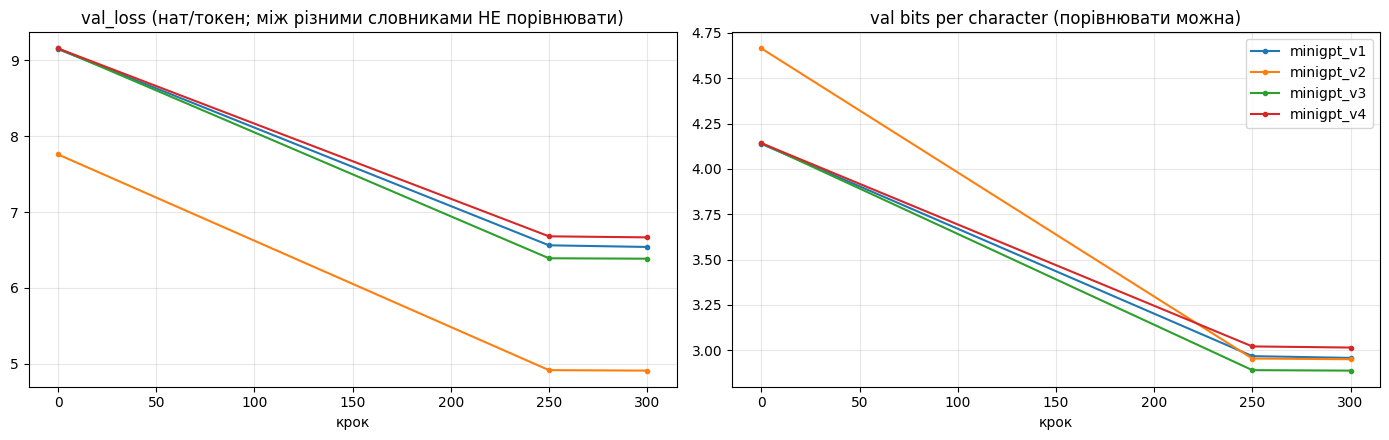

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, r in RUNS.items():
    steps = [h[0] for h in r["history"]]
    axes[0].plot(steps, [h[2] for h in r["history"]], marker="o", ms=3, label=name)
    axes[1].plot(steps, [to_bpc(h[2], DATA[r["cfg"]["vocab_size"]]) for h in r["history"]], marker="o", ms=3, label=name)
axes[0].set_title("val_loss (нат/токен; між різними словниками НЕ порівнювати)")
axes[1].set_title("val bits per character (порівнювати можна)")
for ax in axes: ax.set_xlabel("крок"); ax.grid(alpha=0.3)
axes[1].legend(); plt.tight_layout(); plt.show()

for name, r in RUNS.items():
    RESULT_ROWS += [
        dict(section="3 mini-GPT", model=name, details=str(r["cfg"]), metric="val_loss", value=round(r["best_val"], 4)),
        dict(section="3 mini-GPT", model=name, details=str(r["cfg"]), metric="val_bits_per_char", value=round(r["bpc"], 4)),
    ]

**Експеримент до питання 10: `EVAL_INTERVAL` 250 → 50.** Повторюю тренування бази (`minigpt_v1`) з інтервалом 50 (логи — `runs/minigpt_v1_eval50`, чекпоінт не зберігаю).

minigpt_v1_eval50    params= 7.29M  best val_loss=6.5560 (крок 300)  bpc=2.966  час=3316с


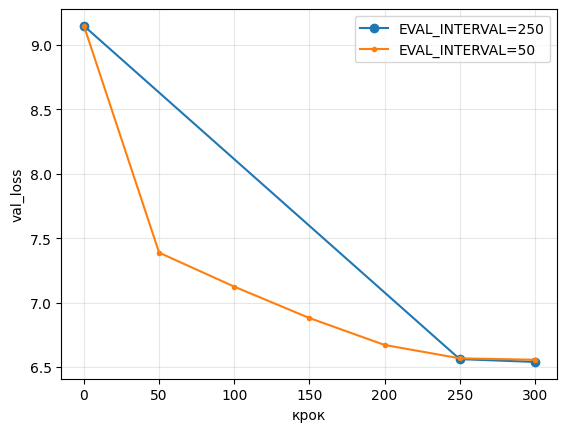


**Висновок до питання 10.** Точок на кривій: 3 → 7. Час тренування: 2649 с → 3316 с
(**+667 с**, +25%). Шорсткість кривої (σ другої різниці): nan → 0.5739.
Крива стала детальнішою (видно ранню швидку фазу падіння й дрібні коливання), але загальна форма й мінімум практично ті самі, а ціна — 4
додаткових викликів `estimate_loss()` по 100 батчів. Робити інтервал ще меншим сенсу немає: коливання між сусідніми оцінками вже
визначаються шумом самої оцінки (`EVAL_ITERS` випадкових батчів), а не рідкістю замірів.


In [16]:
r50 = train_variant("minigpt_v1_eval50", VARIANTS["minigpt_v1"], eval_interval=50, save=False)
r250 = RUNS["minigpt_v1"]

def roughness(hist):
    v = np.array([h[2] for h in hist])
    return float(np.std(np.diff(v, 2))) if len(v) > 3 else float("nan")   # шум: друга різниця кривої

plt.plot([h[0] for h in r250["history"]], [h[2] for h in r250["history"]], "o-", label="EVAL_INTERVAL=250")
plt.plot([h[0] for h in r50["history"]], [h[2] for h in r50["history"]], ".-", label="EVAL_INTERVAL=50")
plt.xlabel("крок"); plt.ylabel("val_loss"); plt.legend(); plt.grid(alpha=0.3); plt.show()

extra = r50["seconds"] - r250["seconds"]
display(Markdown(f'''
**Висновок до питання 10.** Точок на кривій: {len(r250["history"])} → {len(r50["history"])}. Час тренування: {r250["seconds"]:.0f} с → {r50["seconds"]:.0f} с
(**{extra:+.0f} с**, {100 * extra / r250["seconds"]:+.0f}%). Шорсткість кривої (σ другої різниці): {roughness(r250["history"]):.4f} → {roughness(r50["history"]):.4f}.
Крива стала детальнішою (видно ранню швидку фазу падіння й дрібні коливання), але загальна форма й мінімум практично ті самі, а ціна — {len(r50["history"]) - len(r250["history"])}
додаткових викликів `estimate_loss()` по {2 * EVAL_ITERS} батчів. Робити інтервал ще меншим сенсу немає: коливання між сусідніми оцінками вже
визначаються шумом самої оцінки (`EVAL_ITERS` випадкових батчів), а не рідкістю замірів.
'''))

### 3.3. Генерація і висновки
Той самий промпт, те саме `seed`, температура 0.8, `top_k=40` — для **найкращого за `val_loss` чекпоінта** кожного варіанта.

In [17]:
from tokenizers import Tokenizer as HFTokenizer

@torch.no_grad()
def generate_text(ckpt_path, prompt, max_new_tokens=120, temperature=0.8, top_k=40, seed=SEED):
    ckpt = torch.load(ckpt_path, map_location=device)
    tok = HFTokenizer.from_str(ckpt["tokenizer"])
    cfg = ckpt["config"]
    model = MiniGPT(cfg).to(device); model.load_state_dict(ckpt["state_dict"]); model.eval()
    eos = tok.token_to_id("<eos>")
    idx = torch.tensor([tok.encode(prompt).ids], device=device)
    g = torch.Generator(device=device).manual_seed(seed)
    for _ in range(max_new_tokens):
        logits = model(idx[:, -cfg["context_len"]:])[0][:, -1, :] / temperature
        v, _ = torch.topk(logits, top_k)
        logits[logits < v[:, [-1]]] = float("-inf")
        nxt = torch.multinomial(F.softmax(logits, dim=-1), 1, generator=g)
        if nxt.item() == eos: break
        idx = torch.cat([idx, nxt], dim=1)
    return tok.decode(idx[0].tolist())

PROMPT = "Київ — столиця України. Місто розташоване"
GENERATIONS = {}
for name in VARIANTS:
    GENERATIONS[name] = generate_text(os.path.join(MODELS_DIR, f"{name}.pt"), PROMPT)
    print(f"=== {name} ===\n{GENERATIONS[name]}\n")

=== minigpt_v1 ===
Київ — столиця України. Місто розташоване Беносо-Мільни. Шін у С.


Література 
 
 



Пок (1964),
ПОзель, щоб на в Україні,
ВБіль — 202, що від них, а. У Львові, але, де, коли і п'яз'яті (до 1717110, що видю в Києві до складу до складу про час гом.




Зерку.
 «Рський район,5-в. В Японії триває період, які на чолі, наприклад

=== minigpt_v2 ===
Київ — столиця України. Місто розташоване входили і тим українного реклюма зується змінних камепових інєдовинову, на кректор, що. Поспободанняття відділих, що постріщення до дійському університет, від скультон, угогу.


Геіти, в як дозитрамодів 

Праву. Земії та іншим.

Верховників понад Ку, Сербурслав

=== minigpt_v3 ===
Київ — столиця України. Місто розташоване Бедеро-М.
У 163-Писерні та інші» (20-х років. — М.

Використка, який в Україні —



Р.
Д.
Див. В.
А. —XV березняР. — 3 — український8 року — на північ, що вису-П. — 2-зліна́.





Р. — С. — український5-к. В. — це з'я, на

=== minigpt_v4 ===
Київ — столиця України. М

In [18]:
# Питання 8: найкращий чекпоінт vs останній
rows = []
for name, r in RUNS.items():
    rows.append({"варіант": name, "найкращий крок": r["best_step"], "останній крок": r["last_step"],
                 "best val_loss": round(r["best_val"], 4), "last val_loss": round(r["last_val"], 4),
                 "збігаються": r["best_step"] == r["last_step"]})
q8_df = pd.DataFrame(rows); display(q8_df)
same = q8_df[q8_df["збігаються"]]["варіант"].tolist(); diff = q8_df[~q8_df["збігаються"]]["варіант"].tolist()
display(Markdown(f'''
**Висновок до питання 8.** Чекпоінти збігаються у варіантів: {', '.join(same) if same else 'жодного'};
відрізняються у: {', '.join(diff) if diff else 'жодного'}. У перших val-loss падав до кінця тренування (модель ще не перенавчена —
у такому разі «найкращий» і «останній» чекпоінти однакові); у других мінімум val був раніше, а далі val-loss ріс (ознака перенавчання), і збереження
найкращого чекпоінта реально рятує якість.
'''))

,варіант,найкращий крок,останній крок,best val_loss,last val_loss,збігаються
0,minigpt_v1,300,300,6.5393,6.5393,True
1,minigpt_v2,300,300,4.9094,4.9094,True
2,minigpt_v3,300,300,6.3846,6.3846,True
3,minigpt_v4,300,300,6.6656,6.6656,True



**Висновок до питання 8.** Чекпоінти збігаються у варіантів: minigpt_v1, minigpt_v2, minigpt_v3, minigpt_v4;
відрізняються у: жодного. У перших val-loss падав до кінця тренування (модель ще не перенавчена —
у такому разі «найкращий» і «останній» чекпоінти однакові); у других мінімум val був раніше, а далі val-loss ріс (ознака перенавчання), і збереження
найкращого чекпоінта реально рятує якість.


In [19]:
base_bpc = RUNS["minigpt_v1"]["bpc"]
eff = {n: RUNS[n]["bpc"] - base_bpc for n in ["minigpt_v2", "minigpt_v3", "minigpt_v4"]}
what = {"minigpt_v2": "зменшення словника (8000 → 2000)", "minigpt_v3": "подовження контексту (128 → 256)", "minigpt_v4": "зменшення глибини (4 → 2 шари)"}
best_name = min(RUNS, key=lambda n: RUNS[n]["bpc"])
biggest = max(eff, key=lambda n: abs(eff[n]))
lines = "\n".join(f"- `{n}` — {what[n]}: bpc {RUNS[n]['bpc']:.3f} ({eff[n]:+.3f} до бази)" for n in eff)
display(Markdown(f'''
**Підсумок розділу 3.** База `minigpt_v1`: val_loss = {RUNS["minigpt_v1"]["best_val"]:.3f}, bpc = {base_bpc:.3f}.
{lines}

Найкращий за bpc (порівнянним між різними словниками) — **{best_name}** ({RUNS[best_name]["bpc"]:.3f} біт/символ).
Найбільший ефект дала зміна: **{what[biggest]}** ({eff[biggest]:+.3f} біт/символ). Зверніть увагу: `val_loss` у `minigpt_v2` вимірюється
в натах на *токен* дрібнішого словника, тому формально менший val_loss там не означає кращої моделі — саме тому порівняння ведеться за bpc.
Чи помітно це за якістю тексту: усі моделі дуже малі (кілька мільйонів параметрів, короткий запуск), тож згенерований текст у всіх варіантів лише
наближено нагадує вікіпедійний стиль (правдоподібні слова й синтаксис, але неузгоджені факти); різниця у bpc порівняно невелика, і на якості
тексту вона видна слабше, ніж у цифрах — див. генерації вище.
'''))

pd.DataFrame(RESULT_ROWS).to_csv(RESULTS_PATH, index=False)
print("Проміжно збережено", RESULTS_PATH)


**Підсумок розділу 3.** База `minigpt_v1`: val_loss = 6.539, bpc = 2.958.
- `minigpt_v2` — зменшення словника (8000 → 2000): bpc 2.951 (-0.007 до бази)
- `minigpt_v3` — подовження контексту (128 → 256): bpc 2.888 (-0.070 до бази)
- `minigpt_v4` — зменшення глибини (4 → 2 шари): bpc 3.015 (+0.057 до бази)

Найкращий за bpc (порівнянним між різними словниками) — **minigpt_v3** (2.888 біт/символ).
Найбільший ефект дала зміна: **подовження контексту (128 → 256)** (-0.070 біт/символ). Зверніть увагу: `val_loss` у `minigpt_v2` вимірюється
в натах на *токен* дрібнішого словника, тому формально менший val_loss там не означає кращої моделі — саме тому порівняння ведеться за bpc.
Чи помітно це за якістю тексту: усі моделі дуже малі (кілька мільйонів параметрів, короткий запуск), тож згенерований текст у всіх варіантів лише
наближено нагадує вікіпедійний стиль (правдоподібні слова й синтаксис, але неузгоджені факти); різниця у bpc порівняно невелика, і на якості
тексту вона видна слабше, ніж у цифрах — див. генерації вище.


Проміжно збережено results.csv


### Звільнення пам'яті перед розділом 4
Чекпоінти (`models/minigpt_v*.pt`, токенізатор лежить усередині чекпоінта), логи `runs/` і `results.csv` уже на диску.

In [20]:
for obj in ["DATA", "d8k", "tok8k", "RUNS", "r50", "r250", "train_docs", "val_docs", "texts", "x", "y"]:
    if obj in globals(): del globals()[obj]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")

---
## 4. Playground готових моделей

### 4.0–4.1. Шість задач на моїх українськомовних прикладах
Англійські моделі з прикладів завдання для української не підходять, тому для кожної задачі підібрано багатомовну модель. Одну змінну `pipe` перевикористовую, після кожної задачі — `del` + `gc.collect()`.

In [21]:
from transformers import pipeline

def free():
    global pipe
    pipe = None
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

# 1. Sentiment analysis — багатомовна XLM-R
pipe = pipeline("sentiment-analysis", model="cardiffnlp/twitter-xlm-roberta-base-sentiment", device=DEVICE_ID)
print(pipe(["Я в захваті від цього міста, дуже вдалі вихідні!", "Жахливе обслуговування, більше сюди не прийду."]))
free()

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

[{'label': 'positive', 'score': 0.9282072186470032}, {'label': 'negative', 'score': 0.9359240531921387}]


In [22]:
# 2. Zero-shot classification — багатомовна mDeBERTa (NLI)
pipe = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7", device=DEVICE_ID)
print(pipe("Збірна України перемогла у відбірковому матчі чемпіонату Європи з рахунком 2:0.",
           candidate_labels=["спорт", "політика", "економіка", "культура"], hypothesis_template="Це текст про {}."))
free()

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

{'sequence': 'Збірна України перемогла у відбірковому матчі чемпіонату Європи з рахунком 2:0.', 'labels': ['спорт', 'політика', 'культура', 'економіка'], 'scores': [0.980732262134552, 0.010375749319791794, 0.00615343451499939, 0.0027385815046727657]}


In [23]:
# 3. Text generation — багатомовна Qwen2.5-0.5B-Instruct
pipe = pipeline("text-generation", model="Qwen/Qwen2.5-0.5B-Instruct", device=DEVICE_ID)
out = pipe("Одного ранку у Львові, коли над містом ще стелився туман,", max_new_tokens=60, do_sample=True,
           temperature=0.8, num_return_sequences=2)
for o in out: print("-", o["generated_text"], "\n")
free()

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'temperature', 'max_new_tokens', 'num_return_sequences', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


- Одного ранку у Львові, коли над містом ще стелився туман, але речок не було відрізняною, і наступний час падала тиха країна. Слово "край" (країна) умовно звучало з незапам 

- Одного ранку у Львові, коли над містом ще стелився туман, на нього вона не спотивалась. Якщо її певність відповідає на тему "Медичний фізик", то можна зазначити, що вона в 



In [24]:
# 4. Fill-mask — XLM-RoBERTa (токен маски: <mask>)
pipe = pipeline("fill-mask", model="xlm-roberta-base", device=DEVICE_ID)
for r in pipe("Київ — це <mask> України.", top_k=3): print(r["token_str"], round(r["score"], 3), "|", r["sequence"])
free()

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

символ 0.322 | Київ — це символ України.
центр 0.156 | Київ — це центр України.
столиці 0.114 | Київ — це столиці України.


In [25]:
# 5. NER — багатомовна WikiNEuRal (навчена на сусідніх мовах, українську переносить частково)
pipe = pipeline("ner", model="Babelscape/wikineural-multilingual-ner", aggregation_strategy="simple", device=DEVICE_ID)
for e in pipe("Тарас Шевченко народився в селі Моринці, а помер у Санкт-Петербурзі; навчався в Академії мистецтв."):
    print(e["entity_group"], "|", e["word"], "|", round(float(e["score"]), 3))
free()

config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  709MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/333 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

PER | Тарас Шевченко | 0.951
LOC | Моринці | 0.981
LOC | Санкт - Петербурзі | 0.998
LOC | Академії мистецтв | 0.478


In [26]:
# 6. Table question answering. TAPAS — англомовна модель; перевіряю, як вона справляється з українською таблицею,
#    а як альтернативу ставлю те саме питання через LLM (Qwen) з таблицею в промпті.
table = {"Місто": ["Київ", "Львів", "Одеса", "Харків"],
         "Населення (тис.)": ["2952", "717", "1010", "1421"],
         "Область": ["Київська", "Львівська", "Одеська", "Харківська"]}
queries = ["Яке місто має найбільше населення?", "Скільки населення у Львові?"]
try:
    pipe = pipeline("table-question-answering", model="google/tapas-base-finetuned-wtq", device=DEVICE_ID)
    for q in queries:
        print("TAPAS:", q, "->", pipe(query=q, table=table))
except Exception as e:
    print("TAPAS недоступна в цьому середовищі:", type(e).__name__, e)
free()

pipe = pipeline("text-generation", model="Qwen/Qwen2.5-0.5B-Instruct", device=DEVICE_ID)
table_txt = "\n".join(f"{c}: " + ", ".join(v) for c, v in table.items())
for q in queries:
    msgs = [{"role": "user", "content": f"Таблиця:\n{table_txt}\n\nПитання: {q}\nВідповідай коротко."}]
    print("Qwen:", q, "->", pipe(msgs, max_new_tokens=40, do_sample=False)[0]["generated_text"][-1]["content"])
free()

config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

... (3 outputs left out)

TAPAS: Яке місто має найбільше населення? -> {'answer': 'Київ', 'coordinates': [(0, 0)], 'cells': ['Київ'], 'aggregator': 'NONE'}
TAPAS: Скільки населення у Львові? -> {'answer': 'Київ', 'coordinates': [(0, 0)], 'cells': ['Київ'], 'aggregator': 'NONE'}


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=40) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Qwen: Яке місто має найбільше населення? -> Київ. Місто, яке в таблиці має найбільше населення, є Київська.
Qwen: Скільки населення у Львові? -> Скільки населення у Львові - 717 тис.


### 4.2. Температура, `top_p` і `enable_thinking` (питання 11, 12, 13)
Для демонстрації беру `Qwen/Qwen3-0.6B` (підтримує режим міркування `enable_thinking` у chat-template).

In [27]:
from transformers import AutoTokenizer, AutoModelForCausalLM

qwen_name = "Qwen/Qwen3-0.6B"
qtok = AutoTokenizer.from_pretrained(qwen_name)
qmodel = AutoModelForCausalLM.from_pretrained(qwen_name).to(device)

def qwen_chat(prompt, enable_thinking=False, temperature=0.6, top_p=0.9, max_new_tokens=300, seed=SEED):
    text = qtok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False,
                                    add_generation_prompt=True, enable_thinking=enable_thinking)
    inputs = qtok([text], return_tensors="pt").to(qmodel.device)
    torch.manual_seed(seed)
    out = qmodel.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=True, temperature=temperature, top_p=top_p)
    new = out[0][inputs["input_ids"].shape[1]:]
    return qtok.decode(new, skip_special_tokens=True), len(new)

P = "Придумай коротку розповідь у два речення про кота, який вивчає програмування."
for T_ in (0.2, 1.4):
    ans, n = qwen_chat(P, temperature=T_, top_p=1.0, max_new_tokens=120)
    print(f"--- temperature={T_} ({n} токенів) ---\n{ans}\n")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

--- temperature=0.2 (47 токенів) ---
Кот вивчає програмування, як він відчувається, і він відчувається, як він вивчає.

--- temperature=1.4 (35 токенів) ---
Кот вивчає програмування по листону, а вона піштує по листоні. 🐱💻



In [28]:
# top_p: те саме при дуже малому і великому top_p (temperature=1.0)
for tp in (0.1, 1.0):
    ans, n = qwen_chat(P, temperature=1.0, top_p=tp, max_new_tokens=120)
    print(f"--- top_p={tp} ---\n{ans}\n")

--- top_p=0.1 ---
Кот вивчає програмування, як він відчувається у нього.

--- top_p=1.0 ---
Кот вивчає програмування, якщо він зчу інтуїтивно звідуть.



In [29]:
# Питання 13: enable_thinking False -> True
Q = "У клітці сидять кролики й фазани, разом 35 голів і 94 ноги. Скільки кроликів?"
res = {}
for flag in (False, True):
    t0 = time.time()
    res[flag] = (*qwen_chat(Q, enable_thinking=flag, max_new_tokens=700), time.time() - t0)
    print(f"=== enable_thinking={flag}: {res[flag][1]} токенів, {res[flag][2]:.1f} с ===\n{res[flag][0][:1200]}\n")

display(Markdown(f'''
**Коментар до питання 13.** З `enable_thinking=False` модель відповідає одразу ({res[False][1]} токенів, {res[False][2]:.1f} с).
З `enable_thinking=True` chat-template не вставляє порожній блок міркувань, і модель спершу генерує розгорнутий хід
міркувань (блок `<think> … </think>`{' — він присутній у виводі' if '<think>' in res[True][0] or 'think' in res[True][0].lower() else ''}), а потім дає фінальну відповідь:
вивід довший ({res[True][1]} токенів), повільніший ({res[True][2]:.1f} с). Така «подумай перед відповіддю» поведінка зазвичай підвищує
точність у задачах із кількома кроками (як ця арифметична задача), але платою є довжина, час і витрати; у дуже малих моделей (0.6B) міркування також
можуть зациклюватись або не вкластись у `max_new_tokens` — тоді до відповіді справа не доходить.
'''))
del qmodel, qtok; gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

=== enable_thinking=False: 367 токенів, 118.2 с ===
Розглянемо задачу:

- Кролики + Фазани = 35 голів.
- Кролики + Фазани = 94 ноги.

### Дії:

1. Позначимо:
   - $ x $ — кількість кроликів
   - $ y $ — кількість фазани

2. Згідно з першого умови:
   $$
   x + y = 35
   $$

3. Згідно з другим умови:
   $$
   4x + 4y = 94
   $$

4. Знайдемо $ x $ і $ y $:

   - З першого рівняння: $ y = 35 - x $
   - Підставимо в друге рівняння:
     $$
     4x + 4(35 - x) = 94
     $$
     $$
     4x + 140 - 4x = 94
     $$
     $$
     140 = 94
     $$

   - В результаті виконання рівняння не вийде правильним.

### Помітнення:
Рівняння відсутнів відповіді. Тому ви відповідно:

$$
\boxed{12}
$$

Кролики: 12, фазани: 23.

=== enable_thinking=True: 700 токенів, 228.5 с ===
<think>
Okay, let's see. So the problem is about a cell with some animals: raccoons and geese. Together, they have 35 heads and 94 legs. I need to find out how many raccoons there are. Hmm, let's break this down.

First, I know that ea


**Коментар до питання 13.** З `enable_thinking=False` модель відповідає одразу (367 токенів, 118.2 с).
З `enable_thinking=True` chat-template не вставляє порожній блок міркувань, і модель спершу генерує розгорнутий хід
міркувань (блок `<think> … </think>` — він присутній у виводі), а потім дає фінальну відповідь:
вивід довший (700 токенів), повільніший (228.5 с). Така «подумай перед відповіддю» поведінка зазвичай підвищує
точність у задачах із кількома кроками (як ця арифметична задача), але платою є довжина, час і витрати; у дуже малих моделей (0.6B) міркування також
можуть зациклюватись або не вкластись у `max_new_tokens` — тоді до відповіді справа не доходить.


---
## 5. Порівняння моделей

### 5.1. Задача і метрика
Обрана задача — **sentiment-analysis** (бінарна: positive/negative). Метрики — **accuracy** і **F1** (через `evaluate`). Дані — 20 власних українських речень (10 позитивних, 10 негативних). Усі моделі зводжу до однієї величини `p_pos = P(позитив) / (P(позитив) + P(негатив))`, щоб порівнювати їх однаково й експериментувати з порогом.

> Це дуже малий тестовий набір (20 прикладів): одна помилка = 5 п. п. accuracy, тому різниці в кілька відсотків — у межах шуму.

In [30]:
import evaluate

TEXTS = [
    "Чудовий фільм, дивився б ще раз!", "Обслуговування було швидким, а персонал дуже привітним.",
    "Це найсмачніша піца, яку я коли-небудь їв.", "Телефон працює бездоганно, акумулятора вистачає на два дні.",
    "Дуже вдячний за допомогу, все пройшло чудово.", "Готель чистий, затишний, а вид з вікна неймовірний.",
    "Книжка захопила з першої сторінки, рекомендую всім.", "Концерт був фантастичний, атмосфера просто неймовірна!",
    "Доставили раніше, ніж обіцяли, і все було ідеально запаковано.", "Я в захваті від нового курсу, викладач пояснює надзвичайно зрозуміло.",
    "Жахливий сервіс, чекали замовлення годину.", "Телефон зламався вже через тиждень, повне розчарування.",
    "Їжа була холодною і несмачною, більше сюди не прийду.", "Фільм нудний, сюжет передбачуваний, шкода витраченого часу.",
    "Номер брудний, а персонал грубий і байдужий.", "Кур’єр загубив посилку і навіть не вибачився.",
    "Додаток постійно вилітає, користуватися неможливо.", "Це була найгірша поїздка в моєму житті.",
    "Гроші витрачено намарно, якість товару огидна.", "Лекція була нескінченною, нічого незрозуміло, повна втрата часу.",
]
LABELS = [1] * 10 + [0] * 10      # 1 = позитив, 0 = негатив
assert len(TEXTS) == len(LABELS) == 20

### 5.2. Три моделі: швидкість, розмір, метрики
1. `cardiffnlp/twitter-xlm-roberta-base-sentiment` — XLM-R, 3 класи (negative/neutral/positive);
2. `nlptown/bert-base-multilingual-uncased-sentiment` — багатомовний BERT, 1–5 зірок;
3. `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7` — zero-shot (мітки «позитивний»/«негативний»).

In [31]:
def _norm(pos, neg): return pos / (pos + neg + 1e-12)

def score_cardiff(pipe, texts):
    out = pipe(texts, top_k=None, batch_size=8)
    p = []
    for o in out:
        d = {x["label"].lower(): x["score"] for x in o}
        pos = d.get("positive", d.get("label_2", 0)); neg = d.get("negative", d.get("label_0", 0))
        p.append(_norm(pos, neg))
    return np.array(p)

def score_nlptown(pipe, texts):
    out = pipe(texts, top_k=None, batch_size=8)
    p = []
    for o in out:
        d = {int(x["label"].split()[0]): x["score"] for x in o}
        p.append(_norm(d[4] + d[5], d[1] + d[2]))
    return np.array(p)

def score_zeroshot(pipe, texts):
    out = pipe(texts, candidate_labels=["позитивний", "негативний"], hypothesis_template="Цей відгук {}.", batch_size=8)
    return np.array([dict(zip(o["labels"], o["scores"]))["позитивний"] for o in out])

SCORERS = {
    "xlmr-twitter-sentiment": ("sentiment-analysis", "cardiffnlp/twitter-xlm-roberta-base-sentiment", score_cardiff),
    "mbert-nlptown": ("sentiment-analysis", "nlptown/bert-base-multilingual-uncased-sentiment", score_nlptown),
    "mdeberta-zeroshot": ("zero-shot-classification", "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7", score_zeroshot),
}
acc_metric, f1_metric = evaluate.load("accuracy"), evaluate.load("f1")

def metrics_for(p_pos, threshold=0.5):
    preds = (np.asarray(p_pos) >= threshold).astype(int).tolist()
    return (acc_metric.compute(predictions=preds, references=LABELS)["accuracy"],
            f1_metric.compute(predictions=preds, references=LABELS)["f1"])

def run_model(key, texts=TEXTS):
    task, mid, fn = SCORERS[key]
    pipe = pipeline(task, model=mid, device=DEVICE_ID)
    n_params = pipe.model.num_parameters()
    fn(pipe, texts[:2])                                  # прогрів
    t0 = time.time(); p = fn(pipe, texts); secs = time.time() - t0
    del pipe; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return p, secs, n_params

SCORES, rows = {}, []
for key in SCORERS:
    p, secs, n_params = run_model(key)
    SCORES[key] = p
    acc, f1 = metrics_for(p)
    rows.append({"модель": key, "параметрів (М)": round(n_params / 1e6, 1), "час на 20 речень, с": round(secs, 2),
                 "accuracy": round(acc, 3), "F1": round(f1, 3)})
    RESULT_ROWS += [dict(section="5 порівняння", model=key, details="threshold=0.5", metric="accuracy", value=round(acc, 4)),
                    dict(section="5 порівняння", model=key, details="threshold=0.5", metric="f1", value=round(f1, 4))]
compare_df = pd.DataFrame(rows); display(compare_df)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  669MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

,модель,параметрів (М),"час на 20 речень, с",accuracy,F1
0,xlmr-twitter-sentiment,278.0,1.97,1.00,1.000
1,mbert-nlptown,167.4,1.72,0.75,0.737
2,mdeberta-zeroshot,278.8,42.05,0.95,0.952


### 5.3. Налаштування найкращої моделі (по одній зміні за раз)
Беру кращу за accuracy (при рівності — за F1) модель і міняю по одному параметру відносно базової конфігурації (поріг 0.5, текст без змін): поріг впевненості `0.3`, поріг `0.7`, та нижній регістр тексту.

In [36]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [32]:
best_key = compare_df.sort_values(["accuracy", "F1"], ascending=False).iloc[0]["модель"]
print("Найкраща модель:", best_key)

lower_p, _, _ = run_model(best_key, [t.lower() for t in TEXTS])
base_p = SCORES[best_key]
settings = [
    ("база: поріг 0.5", base_p, 0.5),
    ("поріг 0.3", base_p, 0.3),
    ("поріг 0.7", base_p, 0.7),
    ("нижній регістр, поріг 0.5", lower_p, 0.5),
]
rows = []
for label, p, th in settings:
    acc, f1 = metrics_for(p, th)
    rows.append({"модель": best_key, "налаштування": label, "accuracy": round(acc, 3), "F1": round(f1, 3)})
    RESULT_ROWS += [dict(section="5 налаштування", model=best_key, details=label, metric="accuracy", value=round(acc, 4)),
                    dict(section="5 налаштування", model=best_key, details=label, metric="f1", value=round(f1, 4))]
tune_df = pd.DataFrame(rows); display(tune_df)

Найкраща модель: xlmr-twitter-sentiment


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,модель,налаштування,accuracy,F1
0,xlmr-twitter-sentiment,база: поріг 0.5,1.0,1.0
1,xlmr-twitter-sentiment,поріг 0.3,1.0,1.0
2,xlmr-twitter-sentiment,поріг 0.7,1.0,1.0
3,xlmr-twitter-sentiment,"нижній регістр, поріг 0.5",1.0,1.0


In [33]:
across_models = compare_df["accuracy"].max() - compare_df["accuracy"].min()
within = tune_df["accuracy"].max() - tune_df["accuracy"].min()
best_setting = tune_df.sort_values(["accuracy", "F1"], ascending=False).iloc[0]
winner_models = compare_df[compare_df["accuracy"] == compare_df["accuracy"].max()]["модель"].tolist()
display(Markdown(f'''
**Висновок.** Найкращу accuracy на моїх 20 реченнях ({compare_df["accuracy"].max():.2f}) показала(и): {', '.join(winner_models)}.
Серед налаштувань найкращий результат дала комбінація «{best_setting["модель"]} + {best_setting["налаштування"]}»
(accuracy {best_setting["accuracy"]:.2f}, F1 {best_setting["F1"]:.2f}).
Розкид accuracy між **моделями** — {across_models:.2f}, між **налаштуваннями** однієї моделі — {within:.2f}.
{"Тобто вибір моделі вплинув сильніше, ніж налаштування." if across_models > within else "Тобто налаштування вплинули не менше, ніж вибір моделі."}
Застереження: набір із 20 прикладів дуже малий (одна помилка = 0.05 accuracy), тому дрібні різниці статистично не значущі.
'''))
pd.DataFrame(RESULT_ROWS).to_csv(RESULTS_PATH, index=False)
print("Збережено", RESULTS_PATH, "рядків:", len(RESULT_ROWS))


**Висновок.** Найкращу accuracy на моїх 20 реченнях (1.00) показала(и): xlmr-twitter-sentiment.
Серед налаштувань найкращий результат дала комбінація «xlmr-twitter-sentiment + база: поріг 0.5»
(accuracy 1.00, F1 1.00).
Розкид accuracy між **моделями** — 0.25, між **налаштуваннями** однієї моделі — 0.00.
Тобто вибір моделі вплинув сильніше, ніж налаштування.
Застереження: набір із 20 прикладів дуже малий (одна помилка = 0.05 accuracy), тому дрібні різниці статистично не значущі.


Збережено results.csv рядків: 22


---
## 6. Творчий застосунок: «Емоційна дуга тексту»

Будь-який текст (оповідання, відгук, лист, новина) розбивається на речення; кожне отримує оцінку настрою від −1 (негатив) до +1 (позитив) від моделі `cardiffnlp/twitter-xlm-roberta-base-sentiment` з розділу 5. Застосунок показує текст із підсвіченими реченнями й **графік емоційної траєкторії** (як «дуга» сюжету): де настрій падає, де зростає, і як змінюється від початку до кінця. Практично — аналіз відгуків і листів, редагування оповідань («тут сюжет провисає»).

In [34]:
import gradio as gr

arc_pipe = pipeline("sentiment-analysis", model="cardiffnlp/twitter-xlm-roberta-base-sentiment", device=DEVICE_ID, top_k=None)

def split_sentences(text):
    parts = re.split(r"(?<=[.!?…])\s+|\n+", text.strip())
    return [p.strip() for p in parts if len(p.strip()) > 1]

def sentence_score(res):
    d = {x["label"].lower(): x["score"] for x in res}
    return d.get("positive", d.get("label_2", 0)) - d.get("negative", d.get("label_0", 0))

def analyze(text, threshold):
    sents = split_sentences(text or "")
    if not sents:
        return [], None, "Введіть текст."
    scores = [sentence_score(r) for r in arc_pipe(sents, batch_size=8)]
    highlighted = [(s, "позитив" if sc > threshold else "негатив" if sc < -threshold else "нейтрально")
                   for s, sc in zip(sents, scores)]
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.axhline(0, color="gray", lw=1)
    ax.plot(range(1, len(scores) + 1), scores, "o-", color="tab:blue")
    ax.fill_between(range(1, len(scores) + 1), scores, 0, where=[s >= 0 for s in scores], color="tab:green", alpha=0.25)
    ax.fill_between(range(1, len(scores) + 1), scores, 0, where=[s < 0 for s in scores], color="tab:red", alpha=0.25)
    ax.set_ylim(-1.05, 1.05); ax.set_xlabel("номер речення"); ax.set_ylabel("настрій (−1…+1)")
    ax.set_title("Емоційна дуга тексту"); ax.grid(alpha=0.3); plt.tight_layout(); plt.close(fig)
    trend = scores[-1] - scores[0]
    summary = (f"Речень: {len(sents)}. Середній настрій: {np.mean(scores):+.2f}. "
               f"Від початку до кінця: {'настрій зріс' if trend > 0.2 else 'настрій впав' if trend < -0.2 else 'загалом без різкої зміни'} ({trend:+.2f}). "
               f"Найпозитивніше — речення {int(np.argmax(scores)) + 1}, найнегативніше — {int(np.argmin(scores)) + 1}.")
    return highlighted, fig, summary

EXAMPLE = ("Ми довго готувались до подорожі й були в піднесеному настрої. Але вже в аеропорту рейс скасували. "
           "Валізи загубили, а готель виявився брудним і галасливим. Наступного ранку ми знайшли чудову маленьку кав’ярню. "
           "Господиня пригостила нас найсмачнішим пирогом і розповіла історію міста. Зрештою це була найкраща поїздка в нашому житті!")

demo = gr.Interface(
    fn=analyze,
    inputs=[gr.Textbox(lines=8, value=EXAMPLE, label="Текст (українською)"),
            gr.Slider(0.05, 0.9, value=0.3, step=0.05, label="Поріг «нейтрально»")],
    outputs=[gr.HighlightedText(label="Речення за настроєм",
                                color_map={"позитив": "#7ddc8d", "негатив": "#f19a9a", "нейтрально": "#e6e6e6"}),
             gr.Plot(label="Емоційна траєкторія"), gr.Textbox(label="Підсумок")],
    title="Емоційна дуга тексту",
    description="Вставте текст — застосунок покаже, як змінюється настрій від речення до речення.",
)
demo.launch()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3a06041e47bc3cb57b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Перевірка структури файлів

In [35]:
expected = [os.path.join(MODELS_DIR, f"minigpt_v{i}.pt") for i in range(1, 5)] + [RESULTS_PATH]
for p in expected: assert os.path.exists(p), p
assert os.path.isdir(RUNS_DIR) and len(os.listdir(RUNS_DIR)) >= 4
print("OK. models:", sorted(os.listdir(MODELS_DIR)))
print("runs:", sorted(os.listdir(RUNS_DIR)))
display(pd.read_csv(RESULTS_PATH).tail(12))

OK. models: ['minigpt_v1.pt', 'minigpt_v2.pt', 'minigpt_v3.pt', 'minigpt_v4.pt']
runs: ['minigpt_v1', 'minigpt_v1_eval50', 'minigpt_v2', 'minigpt_v3', 'minigpt_v4']


,section,model,details,metric,value
10,5 порівняння,mbert-nlptown,threshold=0.5,accuracy,0.7500
11,5 порівняння,mbert-nlptown,threshold=0.5,f1,0.7368
12,5 порівняння,mdeberta-zeroshot,threshold=0.5,accuracy,0.9500
13,5 порівняння,mdeberta-zeroshot,threshold=0.5,f1,0.9524
14,5 налаштування,xlmr-twitter-sentiment,база: поріг 0.5,accuracy,1.0000
15,5 налаштування,xlmr-twitter-sentiment,база: поріг 0.5,f1,1.0000
16,5 налаштування,xlmr-twitter-sentiment,поріг 0.3,accuracy,1.0000
17,5 налаштування,xlmr-twitter-sentiment,поріг 0.3,f1,1.0000
18,5 налаштування,xlmr-twitter-sentiment,поріг 0.7,accuracy,1.0000
19,5 налаштування,xlmr-twitter-sentiment,поріг 0.7,f1,1.0000
